# The topaz test suite: a walkthrough

This notebook explains what the tests in `test/` check, why each check exists, and where each test's
expected values come from. It runs small pieces of the suite's own code, so the figures and tables come from the real tests.

**What the suite is for.** It catches *silent* numerical regressions, where topaz still runs but gives
different answers, before a release is published. Three such regressions reached v0.3.x releases (a 7× pi
miscalculation, swapping KDTree samples, and drawing identical batches from every data-loader
worker). The tests are built so bugs like these fail loudly.

**How to read it.** Each section covers one folder of `test/`:
1. Running the suite, and how it's configured
2. Fixtures: committed test data
3. `smoke/`: does every command load, parse, and build?
4. `unit/`: numerics on small in-memory arrays
5. `io/`: image and coordinate file formats
6. `integration/`: whole commands on the fixtures
7. Known, tracked bugs (strict xfails)
8. Index of regression tests (bug → fix commit → test)
9. The mutant gate: checking that the tests can fail (and would if those issues regressed)
10. Changing the suite

**Running it yourself.** Run from `test/` (or the repo root) in an environment with topaz installed
(`pip install -e .[test]`) and matplotlib. The outputs saved in this file come from the commit it was
last run on. After changing tests, re-run it (Kernel → Restart & Run All) before committing.

In [1]:
import importlib.util
import json
import subprocess
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({'figure.dpi': 80, 'font.size': 10})

# the repo root is the first parent of the working directory that holds pyproject.toml
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
TEST = REPO / 'test'
FIXTURES = TEST / 'fixtures'
sys.path.insert(0, str(TEST))  # conftest.py does the equivalent for pytest
import _support  # shared helper functions

def shown(path):
    """A path relative to the repo root when it's inside it, so outputs don't record one machine's layout."""
    path = Path(path).resolve()
    return f'<repo>/{path.relative_to(REPO)}' if REPO in path.parents else str(path)

def load_test_module(relative_path):
    """Import one of the suite's test files so its helpers can be reused here."""
    path = TEST / relative_path
    spec = importlib.util.spec_from_file_location(path.stem, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

import topaz
print(f'topaz {topaz.__version__} from {shown(Path(topaz.__file__).parent)}')
print('checkout: {} @ {}{}'.format(*_support.git_describe(REPO)[:2], ' (uncommitted changes)' if _support.git_describe(REPO)[2] else ''))

topaz 0.3.21 from <repo>/topaz
checkout: master @ 79ca221


## 1. Running the suite, and how it's configured

| Command (from the repo root) | Runs |
|---|---|
| `pytest -m "not slow"` | everything CI runs on every Python version (about a minute) |
| `pytest -m slow` | the long-running tests (CI runs these on Python 3.11 only; none exist yet) |
| `pytest -m unit` (or `smoke`, `io`, `integration`) | one category |
| `pytest test/unit/test_metrics.py` | one file; add `::test_name` for one test |
| `pytest -rs -rx` | also lists every skipped and expected-failure test with its reason |

**Prefer `pytest` to `python -m pytest`.** With an editable install (`pip install -e .`) both work.
With a regular install, `python -m pytest` puts the current directory on `sys.path`, so from the repo root the
tests would import the `./topaz` source folder instead of the installed package.
`conftest.py` checks for this and stops the run with an error (see "Safety checks" below).

**Categories.** Each folder's tests get the matching marker automatically (`conftest.py`), so `-m unit`
selects `test/unit/`. Two more markers are set by hand: `cli` on tests that run a whole `topaz` command,
and `slow` on tests too long for every CI leg.

The live count, from `pytest --collect-only` (one function with parameters gives several cases):

In [2]:
pytest_exe = str(Path(sys.executable).with_name('pytest'))
collected = subprocess.run([pytest_exe, '--collect-only', '-q', '-p', 'no:cacheprovider'], cwd=REPO,
                           capture_output=True, text=True, check=True).stdout
nodes = pd.Series([line for line in collected.splitlines() if '::' in line])
cases = pd.DataFrame({
    'folder': nodes.str.split('/').str[1],
    'file': nodes.str.split('::').str[0].str.split('/').str[-1],
    'function': nodes.str.split('::').str[1].str.split('[').str[0],
})
order = {'smoke': 0, 'unit': 1, 'io': 2, 'integration': 3}
counts = (cases.groupby(['folder', 'file'])
          .agg(test_functions=('function', 'nunique'), cases=('function', 'size'))
          .reset_index().sort_values(['folder', 'file'], key=lambda s: s.map(order) if s.name == 'folder' else s))
print(f'{len(cases)} cases from {cases.function.nunique()} test functions in {cases.file.nunique()} files')
counts.set_index(['folder', 'file'])

343 cases from 97 test functions in 20 files


test_functions  cases
folder      file                                                
smoke       test_cli_surface.py                         1      1
            test_commands.py                            4     44
            test_entry_point.py                         3      3
            test_models.py                              7     34
            test_parsers.py                             1      8
unit        test_coordinate_transforms.py               6     16
            test_extraction.py                          9     36
            test_image_numerics.py                      8      9
            test_masks_and_crops.py                     3     18
            test_metrics.py                             4      9
            test_negative_sampling.py                   4     10
            test_particle_geometry.py                   6     68
            test_training_setup.py                      3      8
io          test_coordinate_formats.py                 12     30
            test_image_discovery.py                     6      9
            test_image_formats.py                       6     11
            test_mrc.py                                11     19
integration test_convert_cli.py                         1      4
            test_extract_segment_cli.py                 2      3
            test_train_formats.py                       1      3

### Configuration (`pyproject.toml`)

- `--import-mode=importlib`: test folders are never added to `sys.path`. Without it, any stray folder
  named `test/topaz/` would be imported in place of the real package.
- `--strict-markers`: a misspelled marker is an error
- `-ra`: the end-of-run summary lists everything that didn't pass, including skips and xfails, with reasons.
- `timeout = 600`: a hung test fails after 10 minutes instead of stalling CI (needs `pytest-timeout`,
  installed by the `test` extra).

### Safety checks (`conftest.py` and `_support.py`)

These run before any test and make the run fail loudly when the setup is wrong. A broken setup could
otherwise produce a green run that tested the wrong thing.

1. **Which topaz is being tested.** The topaz that the tests import must be the same file that the
   `topaz` console script imports. This catches `python -m pytest` shadowing a non-editable install, and a stray `topaz/` folder.
   The mutant gate (section 9) sets `TOPAZ_EXPECT_ROOT`, and the check then also requires topaz to come
   from that copy.
2. **Fixture integrity.** Every file under `test/fixtures/` must match its SHA-256 in `MANIFEST.json`.
   Missing, extra and modified files are all errors.
3. **3D capability checks.** Many tests run in both 2D and 3D (the `ndim` fixture). A 3D case is skipped
   only when an explicit inspection of the code says the feature is missing (for example, `extract`'s
   `--dims` option doesn't offer 3). A test is never skipped just because it raised an error, so a
   broken 3D feature fails instead of quietly skipping.

The values these checks see on this machine:

In [3]:
print('topaz under test:', shown(_support.check_install_location()))
print('fixtures verified:', shown(_support.verified_fixtures_dir()))
pd.Series({name: _support.has_capability(name) for name in _support.CAPABILITY_PROBES}, name='available')

topaz under test: <repo>/topaz
fixtures verified: <repo>/test/fixtures


train_3d      False
extract_3d     True
model_3d       True
Name: available, dtype: bool

## 2. Fixtures: the committed test data

`test/fixtures/` holds small synthetic data that the tests read but never write. It was produced once by
`test/fixtures/generate.py`, **running under topaz v0.2.5**, so that:
- every MRC file was written by v0.2.5's writer and must still be readable today;
- the coordinate files in every format (`.star`, `.csv`, `.box`, `.json`) are v0.2.5's own `topaz convert`
  output. They are the expected answers for today's readers and writers.

The data is synthetic and tiny on purpose: it exercises loading, file formats and command plumbing. It is
not meant to train a good model.

In [4]:
manifest = json.loads((FIXTURES / 'MANIFEST.json').read_text())
print('generated with:', manifest['generator'])
files = pd.Series(list(manifest['files']))
used_by_tests = {'2d': 'io, integration', 'io': 'io', '3d': '(not used by any test yet)', 'scores': '(not used by any test yet)'}
summary = files.groupby(files.str.split('/').str[0]).size().rename('files').to_frame()
summary['used by'] = summary.index.map(used_by_tests)
summary

generated with: {'numpy': '1.24.4', 'pandas': '2.0.3', 'python': '3.8.20', 'seed': 20261001, 'topaz': '0.2.5a'}


,files,used by
2d,35,"io, integration"
3d,2,(not used by any test yet)
io,4,io
scores,3,(not used by any test yet)


`2d/` holds 10 micrographs of 128×128 pixels (7 for training, 3 for testing), each with 15 soft-edged
particles plus noise, and the true particle centres. Circles mark the true centres:

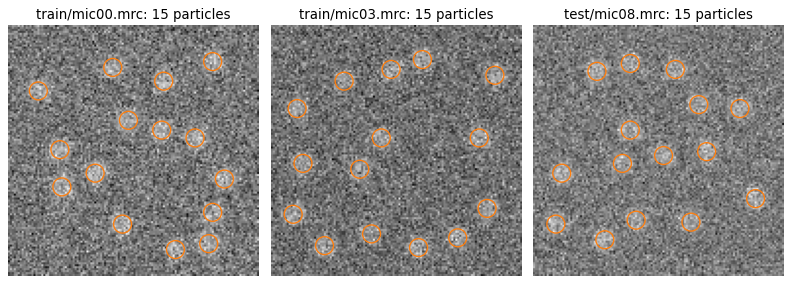

In [5]:
from topaz.utils.data.loader import load_image

truth = pd.read_csv(FIXTURES / '2d' / 'particles.txt', sep='\t')
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
for ax, (name, split) in zip(axes, [('mic00', 'train'), ('mic03', 'train'), ('mic08', 'test')]):
    image = load_image(str(FIXTURES / '2d' / split / f'{name}.mrc'), make_image=False, return_header=False)
    picks = truth[truth.image_name == name]
    ax.imshow(image, cmap='gray')
    ax.scatter(picks.x_coord, picks.y_coord, s=260, facecolors='none', edgecolors='tab:orange', linewidths=1.2)
    ax.set_title(f'{split}/{name}.mrc: {len(picks)} particles')
    ax.axis('off')
plt.tight_layout()

`io/` holds two arrays written by v0.2.5 as MRC (2D and 3D), with `.npy` copies of the same arrays.
`scores/` holds a 2D and a 3D score map with known peaks (`peaks.txt`), used by the `extract` integration test.
`3d/` (one 64³ volume) is generated but **no test uses it yet**. It is there for planned tests of `denoise3d`.

To replace the fixtures on purpose, see section 10.

## 3. `smoke/`: does every command load, parse and build?

These need no data and run first. A failure here usually means the package is broken, not the numerics.

| File | What it checks | Where the expected values come from |
|---|---|---|
| `test_commands.py` | Every module in `topaz.commands` imports, has `name`/`help`/`add_arguments`/`main`, and builds its parser. `topaz --help` and `topaz <command> --help` exit 0. These run through `topaz.main`, so a command file that `main.py` doesn't register fails. | exit code 0 and usage text |
| `test_entry_point.py` | The installed `topaz` script: `--version` agrees with the package metadata, `topaz train --help` works, and bare `topaz` is a usage error (exit 2). These are the only subprocess calls in this folder, because starting `topaz` takes several seconds. | package metadata; exit codes |
| `test_cli_surface.py` | Every option of every command (flag, default, type, choices, nargs, required) matches the snapshot `cli_surface.json`. Any change to the command-line interface, intended or not, shows up as a failure. | committed snapshot |
| `test_parsers.py` | The tutorial's command lines parse to the expected argument values. | values written in the test |
| `test_models.py` | For each architecture, the input region that affects one output pixel (measured with a gradient) is exactly the model's declared `width`, and a `width`-sized input gives one output (2D and 3D). Scoring an image in patches (`predict_in_patches`, used by `extract` and `segment` with `--patch-size`) gives the same scores as scoring it whole, for patches smaller and larger than the receptive field and an image with a blank region. The packaged pretrained detectors and denoisers load with the deprecated `pkg_resources` route blocked, and their parameter counts match. | measured gradient extent; whole-image scores; parameter counts written in the test |

An example snapshot entry (`extract -r`). Changing the default radius would fail `test_cli_surface`:

In [6]:
snapshot = json.loads((TEST / 'smoke' / 'cli_surface.json').read_text())
print(f'{len(snapshot)} commands, {sum(map(len, snapshot.values()))} options in the snapshot')
radius_key = next(k for k in snapshot['extract'] if 'radius' in k and k.startswith('-r'))
pd.Series(snapshot['extract'][radius_key], name=f'extract {radius_key}').to_frame()

21 commands, 235 options in the snapshot


,extract -r|--radius
action,_StoreAction
choices,None
default,None
dest,radius
nargs,None
required,False
type,int


## 4. `unit/`: numerics on small in-memory arrays

Each expected value is computed **independently of the code under test**: by hand, by brute force, with
another library (scikit-learn), or from v0.2.5's behaviour. Most tests run for both 2D and 3D.

| File | What it checks | Where the expected values come from |
|---|---|---|
| `test_particle_geometry.py` | How many pixels a particle of radius *r* covers. Three separate topaz functions compute this (`pixels_given_radius`, `expand_target_points`, `as_mask`) and must all agree. Also `calculate_pi` (the expected fraction of particle pixels). | brute-force count of lattice points within *r*, plus a literal table |
| `test_negative_sampling.py` | With split `'pn'`, a "negative" training crop is never centred on a particle (2,000 draws). A power check: with `'pu'` (no rejection), draws do land on particles at about the coverage rate, so the first test isn't passing by accident. `get_UN_crop`, which training calls, rejects for `'pn'` only. | set membership; a binomial 5σ band |
| `test_training_setup.py` | The training DataLoader gets `worker_init_fn`, and how each method (GE-binomial, GE-KL, PN, PU) sets π, including the fallback to PN when π ≤ the observed positive fraction. | identity check; arithmetic in the test |
| `test_masks_and_crops.py` | Particle masks with overlapping and edge particles; crops at edges and corners, with zero padding; the training dataset's positive fraction and crop centres. | brute-force disc union; `np.pad` + slicing; a binomial band |
| `test_extraction.py` | Non-maximum suppression (NMS); matching predictions to targets (strictly closer than the radius, one-to-one); the extraction radius search, in 2D and 3D. | brute-force greedy NMS; hand-placed peaks |
| `test_metrics.py` | Average precision and the precision-recall curve, for float32 and float64 input, with tied scores, and with targets no prediction matched. | `sklearn.metrics.average_precision_score`; hand-computed cases |
| `test_image_numerics.py` | Affine normalization (exact); the fixed parts of the GMM fit; Fourier downsampling; 8-bit quantization. | algebra; a cosine that must survive downsampling |
| `test_coordinate_transforms.py` | Box ↔ centre conversion, y inversion, coordinate scaling, `mirror_y_axis`. | arithmetic in the test |

### Example: the particle footprint (the M1 bug)

The pixels within radius 3 of a centre, counted by brute force. Every topaz implementation must give the
same count. The regression fixed in `9029e08` built a 3D grid even for 2D images and gave 29 × 7 = 203,
which made the estimated particle fraction π seven times too large.

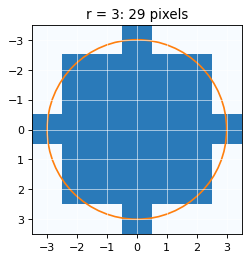

brute force: 29 | pixels_given_radius(3, dims=2): 29 | literal table: 29


In [7]:
from topaz.stats import pixels_given_radius

geometry = load_test_module('unit/test_particle_geometry.py')
r = 3
offsets = geometry.lattice_offsets(r, 2)  # the test's own brute-force oracle
grid = np.zeros((2 * r + 1, 2 * r + 1))
for dy, dx in offsets:
    grid[dy + r, dx + r] = 1

fig, ax = plt.subplots(figsize=(3.4, 3.4))
ax.imshow(grid, cmap='Blues', vmin=0, vmax=1.4, extent=(-r - .5, r + .5, r + .5, -r - .5))
ax.add_patch(plt.Circle((0, 0), r, fill=False, color='tab:orange', lw=1.5))
ax.set_xticks(range(-r, r + 1)); ax.set_yticks(range(-r, r + 1)); ax.grid(color='white', lw=0.5)
ax.set_title(f'r = {r}: {len(offsets)} pixels')
plt.show()
print('brute force:', len(offsets), '| pixels_given_radius(3, dims=2):', pixels_given_radius(3, dims=2),
      '| literal table:', geometry.LATTICE_COUNTS[2][3])

### Example: negatives avoid particles (the M2 bug)

This uses the test's own setup: a 64×64 image with particles on a grid covering about 40% of it. On the
left, the positions `'pn'` sampling chose for negative crops; none may fall on a particle. On the right,
unconstrained `'pu'` sampling, which should hit particles at about the coverage rate. The regression fixed
in `fc28858` unpacked the KD-tree result in the wrong order, so the left panel looked like the right one.

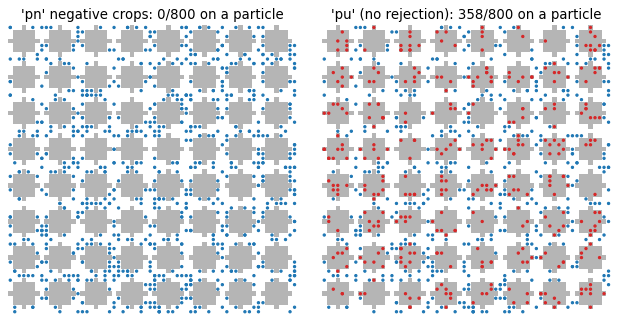

In [8]:
sampling = load_test_module('unit/test_negative_sampling.py')
pn_image, positives = sampling.make_image('pn', 2)
pu_image, _ = sampling.make_image('pu', 2)
negatives = sampling.draw(pn_image.get_random_negative_crop_indices, 2, n=800)
uniform = sampling.draw(pu_image.get_random_crop_indices, 2, n=800)

particle_mask = np.zeros((sampling.SIZE,) * 2)
for y, x in positives:
    particle_mask[y, x] = 1
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, points, title in [(axes[0], negatives, "'pn' negative crops"), (axes[1], uniform, "'pu' (no rejection)")]:
    hits = sum(p in positives for p in points)
    ax.imshow(particle_mask, cmap='Greys', vmin=0, vmax=2.5)
    ys, xs = np.array(points).T
    ax.scatter(xs, ys, s=4, c=['tab:red' if p in positives else 'tab:blue' for p in points])
    ax.set_title(f'{title}: {hits}/{len(points)} on a particle')
    ax.axis('off')
plt.tight_layout()

### Example: NMS and the extraction radius

NMS keeps the highest score, removes every pixel within radius *r* of it, and repeats. Here it runs on the
2D score map from the fixtures, keeping scores above 1.5. The top-left peaks are exactly 6 pixels apart, so
*r* = 5 keeps both and *r* = 6 removes the weaker one. `test_extraction.py` checks NMS against a
brute-force version of the same rule.

NMS removes *pixels*, not particles. At *r* = 6 the weaker peak's neighbour, one pixel further out (7 px
from the stronger peak), is not removed. It scores about 0.4, so a threshold below that would still pick
it, close to the suppressed peak. The 1.5 threshold here keeps the figure about the radius alone.

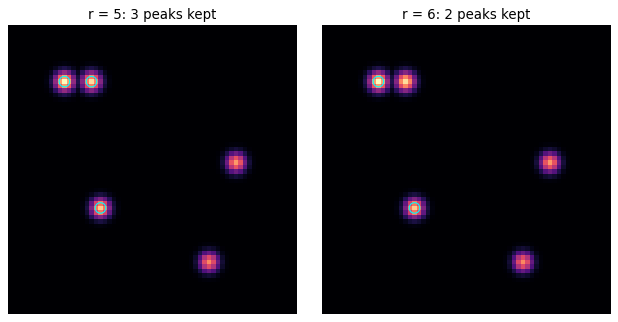

In [9]:
from topaz import mrc
from topaz.algorithms import non_maximum_suppression

with open(FIXTURES / 'scores' / 'scores2d.mrc', 'rb') as f:
    score_map = np.squeeze(mrc.parse(f.read())[0])

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, radius in zip(axes, [5, 6]):
    scores, coords = non_maximum_suppression(score_map, radius, threshold=1.5)
    ax.imshow(score_map, cmap='magma', vmin=-10)
    ax.scatter(coords[:, 0], coords[:, 1], s=90, facecolors='none', edgecolors='cyan')  # coords are (x, y)
    ax.set_title(f'r = {radius}: {len(scores)} peaks kept')
    ax.axis('off')
plt.tight_layout()

### Example: a hand-computed precision-recall curve

Five predictions ranked by score; the 1st and 3rd are hits. Precision at each hit is 1/1 and 2/3, so
average precision is (1 + 2/3) / 2 = 0.833. `test_metrics.py` asserts exactly this, and separately compares
random cases with scikit-learn, in both float32 and float64. The float64 comparison catches the bug fixed
in `5cdf496`, where float64 input was sorted wrongly (0.14 instead of 0.71).

In [10]:
from topaz.metrics import precision_recall_curve

target = np.array([1, 0, 1, 0, 0], dtype=np.float32)
score = np.array([0.9, 0.8, 0.7, 0.6, 0.5], dtype=np.float32)
precision, recall, threshold, auprc = precision_recall_curve(target, score)
print(f'average precision = {auprc:.4f}  (hand-computed: {(1 + 2/3) / 2:.4f})')
pd.DataFrame({'score': threshold, 'hit': target.astype(int), 'precision': precision.round(3), 'recall': recall.round(3)})

average precision = 0.8333  (hand-computed: 0.8333)


,score,hit,precision,recall
0,0.9,1,1.000,0.5
1,0.8,0,0.500,0.5
2,0.7,1,0.667,1.0
3,0.6,0,0.500,1.0
4,0.5,0,0.400,1.0


## 5. `io/`: image and coordinate file formats

| File | What it checks | Where the expected values come from |
|---|---|---|
| `test_mrc.py` | Write → read round trip (2D/3D) with header statistics. Reading the data types other software writes (int8, int16, float32, uint16, float16). Extended headers. Files written by v0.2.5. A header passed in must describe the new data. Pixel size after downsampling, through `downsample_file` and `topaz preprocess -s`. | numpy statistics; v0.2.5-written files; arithmetic |
| `test_image_formats.py` | TIFF round trip (exact), PNG (within one 8-bit step), JPEG (lossy, so scale and type only); `standardize`; the type `load_image` returns; re-saving a TIFF or PNG as MRC. | round trip; quantization step size |
| `test_coordinate_formats.py` | Reading and writing every coordinate format (coord/txt, star, csv, box, json), compared with **v0.2.5's output for the same particles**. Scores survive a round trip, 3D keeps `z_coord`, and image-name extensions are stripped correctly. | v0.2.5's files in `fixtures/2d/` |
| `test_image_discovery.py` | Finding training images in a folder of mixed formats, `--image-ext`, the error when one name exists in two formats, pixel counts per format, and folder vs. list file. | arithmetic in the test |

Coordinate files are compared after parsing (same columns, rows and values), not byte for byte, so harmless
formatting differences don't fail the tests.

### Example: the pixel size after downsampling

Before the fix in `79c58ff`/`f02b728`, a downsampled MRC kept the original pixel size in its header.
This is the same setup as `test_downsample_file_header`:

In [11]:
from topaz.utils.image import downsample_file

mrc_tests = load_test_module('io/test_mrc.py')
with tempfile.TemporaryDirectory() as tmp:
    source, small = Path(tmp) / 'mic.mrc', Path(tmp) / 'small.mrc'
    data = np.random.default_rng(0).standard_normal((1, 256, 256)).astype(np.float32)
    with open(source, 'wb') as f:
        mrc.write(f, data, header=mrc_tests.realistic_header((256, 256), 1.06))
    downsample_file(str(source), 4, str(small), False)
    before, after = mrc_tests.parse_file(source)[1], mrc_tests.parse_file(small)[1]
pd.DataFrame({'pixels': [f'{h.nx}×{h.ny}' for h in (before, after)],
              'pixel size (Å)': [round(h.xlen / h.mx, 4) for h in (before, after)]},
             index=['original', 'downsampled 4×'])

,pixels,pixel size (Å)
original,256×256,1.06
downsampled 4×,64×64,4.24


## 6. `integration/`: whole commands on the fixtures

These run real `topaz` commands through `topaz.main` inside the test process. That is the same
argument-parsing and command code a user runs, without the several-second interpreter start-up per call.

| File | What it checks |
|---|---|
| `test_convert_cli.py` | `topaz convert --invert-y` on MRC and TIFF micrographs, with `--image-ext` given as `mrc`, `.mrc`, `tiff` or omitted. y is mirrored about the last row, and applying it twice gives the original. (It crashed on every input before `14266bf`.) |
| `test_train_formats.py` | `topaz train` for one short epoch on folders of float32 TIFF, uint16 TIFF and PNG micrographs converted from the fixtures. Checks that all 7 training and 3 test micrographs load and that the test metrics are finite numbers. (It crashed on non-MRC folders before `78a0a03`.) |
| `test_extract_segment_cli.py` | `topaz extract -m none` on the 2D and 3D score-map fixtures writes exactly the known peaks above the threshold, with their scores, into an existing output directory. (That crashed before `5d59ae4`.) `topaz segment --patch-size` writes the same score map as segmenting the whole micrograph. (That crashed before `edba979`.) |

The training run checks that training works end to end on each format. It deliberately doesn't judge the
model's *quality*: that needs real data, and is done by hand before a release.

## 7. Known, tracked bugs (strict xfails)

One test in `test_extraction.py`, `test_patched_nms_matches_unpatched`, is marked `xfail(strict=True)` and
runs as two cases (2D and 3D). It covers the patch-by-patch mode of NMS (`NonMaximumSuppression` with a
`patch_size`), which has several bugs. No command uses that mode, so nothing a user can run is affected.
Scoring in patches (`--patch-size`) is a different code path and is tested in `smoke/test_models.py`.

*Strict* means that if one of these starts passing, the run **fails**. This forces whoever fixes the bug to
remove the marker, so the test then guards the fix. `pytest -rx` lists them with their reasons.

## 8. Index of regression tests

Every bug fixed alongside this suite has a test that fails when the fix is reverted.

| Bug | Fixed in | Test(s) |
|---|---|---|
| 2D particle pixel count inflated ×(2r+1); π 7× too high | `9029e08` | `unit/test_particle_geometry.py` (mutant M1) |
| KD-tree result unpacked in the wrong order; negatives sampled on particles | `fc28858` | `unit/test_negative_sampling.py::test_negatives_avoid_positives` (mutant M2) |
| `worker_init_fn` not passed; every worker produced identical batches | `67cecc2` | `unit/test_training_setup.py::test_train_loader_passes_worker_init_fn` (mutant M3) |
| Pretrained denoisers loaded only through deprecated `pkg_resources` | `55ec17a` | `smoke/test_models.py::test_pretrained_denoiser_loads` |
| Saving a TIFF/PNG as MRC crashed (header `None`) | `79c58ff` | `io/test_image_formats.py::test_headerless_image_saved_as_mrc` |
| MRC header kept stale statistics and the original pixel size | `79c58ff`, `f02b728` | `io/test_mrc.py`: `test_write_with_header_describes_new_data`, `test_resize_header_scales_pixel_size`, `test_downsample_file_header`, `test_preprocess_cli_header` |
| PNG/JPEG loaded as raw 0–255 instead of the original values | `a841f62` | `io/test_image_formats.py`: `test_png_roundtrip_unquantized`, `test_standardize`, `test_make_image_returns_pil` |
| Average precision wrong for float64 input | `5cdf496` | `unit/test_metrics.py::test_average_precision_matches_sklearn` |
| Reading VIA `.csv` crashed on pandas ≥ 2 | `ef3b873` | `io/test_coordinate_formats.py::test_read_v025_file[particles.csv]` |
| Coordinate writers dropped `z_coord` | `ef3b873` | `io/test_coordinate_formats.py::test_roundtrip_3d_keeps_z` |
| `convert --invert-y` crashed on every input | `14266bf` | `integration/test_convert_cli.py::test_invert_y`, `unit/test_coordinate_transforms.py::test_mirror_y_axis` |
| `train` crashed on TIFF/PNG micrograph folders | `78a0a03` | `integration/test_train_formats.py`, `io/test_image_discovery.py` |
| 3D extraction radius search scored nothing (targets lost z, `dims` ignored, radius doubled) | `5d59ae4` | `unit/test_extraction.py`: `test_radius_search_scores_the_extraction_radius[3d]`, `test_find_opt_radius_prefers_non_suppressing_radius[3d]` |
| Patch scoring crashed on a blank patch | `edba979` | `smoke/test_models.py::test_patched_scores_match_whole_image` |
| `segment --patch-size` crashed on every input | `edba979` | `integration/test_extract_segment_cli.py::test_segment_in_patches_matches_whole_image` |
| `extract` crashed when `--output` was an existing directory | `5d59ae4` | `integration/test_extract_segment_cli.py::test_extract_finds_known_peaks` |
| `preprocess` crashed on MRC files with no pixel size in the header (division by zero; found on the tutorial data before release) | `79ca221` | `io/test_mrc.py`: `test_resize_header_without_pixel_size`, `test_resize_header_sampling_missing_but_cell_length_present`, `test_resize_header_with_empty_grid` |

## 9. The mutant gate: checking that the tests can fail

A test that can't fail protects nothing. The **mutant gate** puts three real past bugs back (M1–M3 in the
table above) and confirms the tests catch each one:

1. Copy the working-tree `topaz/` package to a temporary folder and run the fast suite against it (the
   *control* run). It must pass; otherwise a suite that is already failing would "catch" everything.
2. For each patch in `test/mutants/`, apply it to a fresh copy and run the suite again. The mutant counts
   as **caught** only if every test listed for it in `mutants.json` fails with an assertion failure.
   An import error or a skip doesn't count.

Your own checkout is never modified. Run it with `python test/release/checks.py mutants`; it takes a few
minutes. It is run by hand before a release, not in CI.

Each patch is the reverse of its fix commit. M1, for example:

In [12]:
print((TEST / 'mutants' / 'M1_pixels_given_radius_3d_grid.patch').read_text())
mutant_list = json.loads((TEST / 'mutants' / 'mutants.json').read_text())['mutants']
pd.DataFrame([{'mutant': m['id'], 'fix commit': m['fix_commit'], 'bug': m['bug'], 'tests that must fail': len(m['catchers'])}
              for m in mutant_list]).set_index('mutant')

diff --git a/topaz/stats.py b/topaz/stats.py
index df8d83f..90d398b 100644
--- a/topaz/stats.py
+++ b/topaz/stats.py
@@ -16,16 +16,13 @@ from topaz.utils.image import downsample, save_image
 
 def pixels_given_radius(radius, dims=2):
     '''Given a radius, calculate the number of pixels in a particle.'''
-    filter_range = torch.arange(start=-radius, end=radius+1)
-    grid = torch.meshgrid([filter_range]*dims, indexing='xy')
-    xgrid, ygrid = grid[0], grid[1]
-    d2 = xgrid**2 + ygrid**2
+    grid = np.linspace(-radius, radius, 2*radius+1)
+    xx,yy,zz = np.meshgrid(grid, grid, grid)
+    d2 = xx**2 + yy**2
     if dims == 3:
-        zgrid = grid[2]
-        d2 += zgrid**2
-    mask = (d2 <= radius**2).int()
-    mask_size = mask.sum().item()
-    return mask_size
+        d2 += zz**2
+    mask = (d2 <= radius**2).astype(int)
+    return mask.sum()
 
 
 def calculate_pi(expected_num_particles, radius, total_pixels, dims=2):



,fix commit,bug,tests that must fail
mutant,,,
M1,9029e08,"pixels_given_radius always builds a 3D grid, i...",3
M2,fc28858,"KDTree.query result unpacked as (idx, dist), s...",1
M3,67cecc2,worker_init_fn not passed to the training Data...,1


The result of running the gate (set `RUN_MUTANT_GATE = False` to skip it; it takes a few minutes):

In [13]:
RUN_MUTANT_GATE = True

if RUN_MUTANT_GATE:
    checks = load_test_module('release/checks.py')
    summary, detail = checks.mutants(verbose=False)
    display(pd.DataFrame(summary).set_index('mutant'))
    display(pd.DataFrame(detail).set_index(['mutant', 'catcher']))

,caught,pytest_rc,failed_tests,total_tests
mutant,,,,
M1,True,1,19,343
M2,True,1,8,343
M3,True,1,1,343


status  n_tests
mutant catcher                                                            
M1     test_particle_geometry::test_pixels_given_radiu...  caught        5
       test_particle_geometry::test_implementations_ag...  caught        5
       test_particle_geometry::test_calculate_pi[2d        caught        9
M2     test_negative_sampling::test_negatives_avoid_po...  caught        2
M3     test_training_setup::test_train_loader_passes_w...  caught        1

## 10. Changing the suite

**Adding a test.** Put it in the folder for its category; the marker is applied automatically. If it
should run in 2D and 3D, take the `ndim` fixture, and call `require('<capability>', ndim)` from `_support`
if the 3D case needs a feature that may be missing. For a long test, add `@pytest.mark.slow`. In the
docstring, say what behaviour it checks and where its expected value comes from. If it guards a fixed
bug, name the bug and the release it was fixed in.

**An intended change to the command-line options.** `test_cli_surface` will fail. Regenerate the snapshot
and review the diff before committing:

    TOPAZ_UPDATE_SNAPSHOT=1 pytest test/smoke/test_cli_surface.py
    git diff test/smoke/cli_surface.json

**Replacing the fixtures.** Only on purpose, since many tests depend on their exact contents. Run
`generate.py` with the Python of an environment that has topaz v0.2.5 installed. It refuses to run under
any other version and rewrites `MANIFEST.json`. Review the diff.

    PYTHONNOUSERSITE=1 /path/to/topaz-0.2.5-env/bin/python test/fixtures/generate.py

**Adding a mutant.** Save the reverse of the fix as a patch in `test/mutants/` and add an entry to
`mutants.json` listing the tests that must fail. Then run the gate. If later changes touch the same code,
a patch may stop applying; the gate reports that rather than skipping it, and the patch must be regenerated.

**Before committing changes to tests:** run `pytest -m "not slow"`, run the mutant gate if you touched
anything that a mutant's tests cover, and re-run this notebook so its outputs match.